# Bước 4. Phân lớp đơn hàng giá trị cao dựa trên kết quả khai phá luật

Đầu vào: 3 bộ dữ liệu tạo ở bước 3:
- `dataset_A_baseline.csv`: 4 thuộc tính cơ bản (chọn ở bước 1)
- `dataset_B_pp1.csv`: 4 thuộc tính cơ bản + 3 đặc trưng từ luật phương pháp 1 (AR1–AR3)
- `dataset_C_pp2.csv`: 4 thuộc tính cơ bản + 3 đặc trưng từ luật phương pháp 2 (MD1–MD3)

In [1]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.4f}'.format)

## 1. Ba bộ dữ liệu và ba mô hình

| Bộ dữ liệu | Đặc trưng |
|---|---|
| A. Baseline | 4 thuộc tính cơ bản: `n_subcats`, `has_furniture`, `has_technology`, `has_office_supplies` |
| B. Baseline + luật PP1 | A + `AR1`, `AR2`, `AR3` (Apriori một chiều) |
| C. Baseline + luật PP2 | A + `MD1`, `MD2`, `MD3` (luật đa chiều) |

Ba mô hình: **Logistic Regression**, **Decision Tree** (độ sâu tối đa 5), **Random Forest** (300 cây). Mỗi bộ được chia train/test theo cột `tap` (giữ nguyên cách chia của bước 3; luật đã được khai phá chỉ trên tập train).

In [4]:
bo_du_lieu = {
    'A. Baseline': pd.read_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_A_baseline.csv'),
    'B. Baseline + luật PP1': pd.read_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_B_pp1.csv'),
    'C. Baseline + luật PP2': pd.read_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_C_pp2.csv'),
}

for ten_bo, bo in bo_du_lieu.items():
    print(ten_bo, bo.shape, '| đặc trưng:', [c for c in bo.columns if c not in ['order_id', 'tap', 'high_value']])

bo_du_lieu['B. Baseline + luật PP1'].head()

A. Baseline (4922, 7) | đặc trưng: ['n_subcats', 'has_furniture', 'has_technology', 'has_office_supplies']
B. Baseline + luật PP1 (4922, 10) | đặc trưng: ['n_subcats', 'has_furniture', 'has_technology', 'has_office_supplies', 'AR1', 'AR2', 'AR3']
C. Baseline + luật PP2 (4922, 10) | đặc trưng: ['n_subcats', 'has_furniture', 'has_technology', 'has_office_supplies', 'MD1', 'MD2', 'MD3']


,order_id,tap,n_subcats,has_furniture,has_technology,has_office_supplies,AR1,AR2,AR3,high_value
0,CA-2017-143609,train,1,1,0,0,0,1,0,1
1,CA-2018-161046,train,4,0,1,1,0,0,0,1
2,US-2018-146906,train,1,0,1,0,0,0,1,1
3,CA-2018-103765,train,1,0,0,1,0,0,0,0
4,US-2016-130519,train,3,1,0,1,0,0,0,0


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

mo_hinh = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}

## 2. Huấn luyện và đánh giá trên tập test

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

ket_qua = []
du_doan = {}     # lưu dự đoán để dùng cho kiểm định ở mục 3
for ten_mh, mh in mo_hinh.items():
    for ten_bo, bo in bo_du_lieu.items():
        train = bo[bo['tap'] == 'train']
        test = bo[bo['tap'] == 'test']
        cot = [c for c in bo.columns if c not in ['order_id', 'tap', 'high_value']]

        mh.fit(train[cot], train['high_value'])
        xac_suat = mh.predict_proba(test[cot])[:, 1]
        nhan = (xac_suat >= 0.5).astype(int)
        du_doan[(ten_mh, ten_bo)] = (xac_suat, nhan)
        ket_qua.append({'Mô hình': ten_mh, 'Bộ dữ liệu': ten_bo,
                        'Accuracy': accuracy_score(test['high_value'], nhan),
                        'Precision': precision_score(test['high_value'], nhan),
                        'Recall': recall_score(test['high_value'], nhan),
                        'F1': f1_score(test['high_value'], nhan),
                        'AUC': roc_auc_score(test['high_value'], xac_suat)})

ket_qua = pd.DataFrame(ket_qua)
ket_qua

,Mô hình,Bộ dữ liệu,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,A. Baseline,0.7513,0.7148,0.8354,0.7704,0.8162
1,Logistic Regression,B. Baseline + luật PP1,0.7685,0.8070,0.7053,0.7527,0.8339
2,Logistic Regression,C. Baseline + luật PP2,0.7452,0.7516,0.7317,0.7415,0.8274
3,Decision Tree,A. Baseline,0.7513,0.7148,0.8354,0.7704,0.8150
4,Decision Tree,B. Baseline + luật PP1,0.7655,0.7806,0.7378,0.7586,0.8294
5,Decision Tree,C. Baseline + luật PP2,0.7421,0.7990,0.6463,0.7146,0.8251
6,Random Forest,A. Baseline,0.7513,0.7148,0.8354,0.7704,0.8157
7,Random Forest,B. Baseline + luật PP1,0.7726,0.7913,0.7398,0.7647,0.8346
8,Random Forest,C. Baseline + luật PP2,0.7411,0.7883,0.6585,0.7176,0.8243


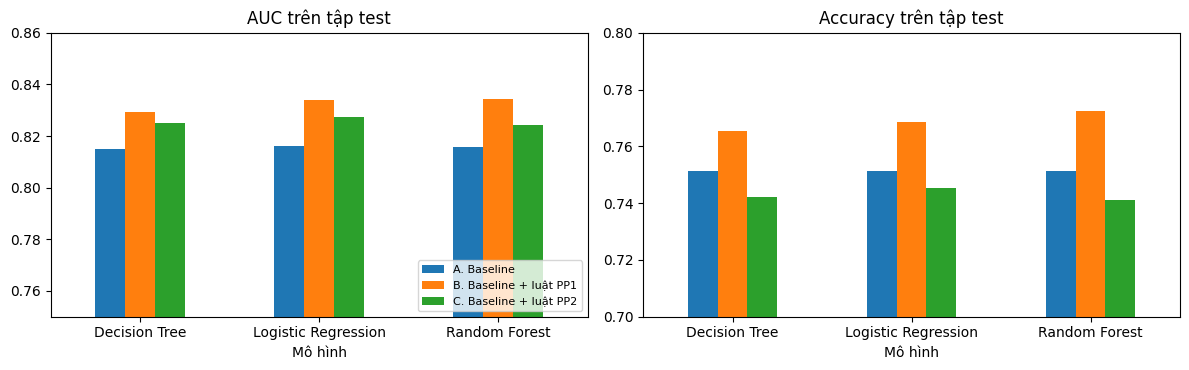

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ket_qua.pivot(index='Mô hình', columns='Bộ dữ liệu', values='AUC').plot(kind='bar', ax=ax[0], rot=0, title='AUC trên tập test')
ax[0].set_ylim(0.75, 0.86)
ax[0].legend(loc='lower right', fontsize=8)
ket_qua.pivot(index='Mô hình', columns='Bộ dữ liệu', values='Accuracy').plot(kind='bar', ax=ax[1], rot=0, title='Accuracy trên tập test', legend=False)
ax[1].set_ylim(0.70, 0.80)
plt.tight_layout()

## 3. Kiểm định thống kê

Chênh lệch giữa các bộ dữ liệu khá nhỏ, nên cần kiểm tra xem nó là thật hay chỉ do tập test tình cờ. Hai kiểm định, đều so sánh **bộ B (hoặc C) với bộ A** trên cùng tập test:

- **Kiểm định McNemar** (cho accuracy): đếm số đơn mà mô hình A đúng nhưng B sai (b) và số đơn A sai nhưng B đúng (c). Nếu hai mô hình tốt như nhau thì b và c xấp xỉ bằng nhau. Dùng dạng chính xác (kiểm định nhị thức với xác suất 0,5).
- **Bootstrap cho AUC**: lấy mẫu có hoàn lại từ tập test 1.000 lần, mỗi lần tính chênh lệch AUC giữa B và A. Nếu khoảng tin cậy 95% của chênh lệch nằm hoàn toàn trên 0 thì B tốt hơn A một cách có ý nghĩa.

In [8]:
from scipy.stats import binomtest

y_test = test['high_value'].values   # ba bộ dùng chung một tập test
rng = np.random.default_rng(42)
mau_bootstrap = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]

kiem_dinh = []
for ten_mh in mo_hinh:
    xs_a, nhan_a = du_doan[(ten_mh, 'A. Baseline')]
    for ten_bo in ['B. Baseline + luật PP1', 'C. Baseline + luật PP2']:
        xs_b, nhan_b = du_doan[(ten_mh, ten_bo)]

        # McNemar (dạng chính xác)
        a_dung_b_sai = int(((nhan_a == y_test) & (nhan_b != y_test)).sum())
        a_sai_b_dung = int(((nhan_a != y_test) & (nhan_b == y_test)).sum())
        p_mcnemar = binomtest(a_sai_b_dung, a_dung_b_sai + a_sai_b_dung, 0.5).pvalue

        # Bootstrap chênh lệch AUC
        chenh = [roc_auc_score(y_test[i], xs_b[i]) - roc_auc_score(y_test[i], xs_a[i]) for i in mau_bootstrap]

        kiem_dinh.append({'Mô hình': ten_mh, 'So sánh': ten_bo[:1] + ' vs A',
                          'A đúng, B sai': a_dung_b_sai, 'A sai, B đúng': a_sai_b_dung, 'p McNemar': p_mcnemar,
                          'Chênh lệch AUC': roc_auc_score(y_test, xs_b) - roc_auc_score(y_test, xs_a),
                          'KTC 95% thấp': np.percentile(chenh, 2.5), 'KTC 95% cao': np.percentile(chenh, 97.5)})

kiem_dinh = pd.DataFrame(kiem_dinh)
kiem_dinh

,Mô hình,So sánh,"A đúng, B sai","A sai, B đúng",p McNemar,Chênh lệch AUC,KTC 95% thấp,KTC 95% cao
0,Logistic Regression,B vs A,64,81,0.1837,0.0177,0.0074,0.0286
1,Logistic Regression,C vs A,64,58,0.6510,0.0113,0.0010,0.0214
2,Decision Tree,B vs A,48,62,0.2150,0.0144,0.0023,0.0271
3,Decision Tree,C vs A,93,84,0.5478,0.0101,0.0012,0.0192
4,Random Forest,B vs A,47,68,0.0617,0.0189,0.0080,0.0303
5,Random Forest,C vs A,100,90,0.5139,0.0086,-0.0016,0.0190


## 4. Mô hình dùng các đặc trưng từ luật như thế nào

Xem mức độ quan trọng của từng đặc trưng trong mô hình Random Forest của bộ B (giảm trung bình độ không thuần khiết Gini khi tách theo đặc trưng đó).

,0
n_subcats,0.3413
has_furniture,0.1743
has_technology,0.1459
AR2,0.1283
AR1,0.0835
has_office_supplies,0.0645
AR3,0.0622


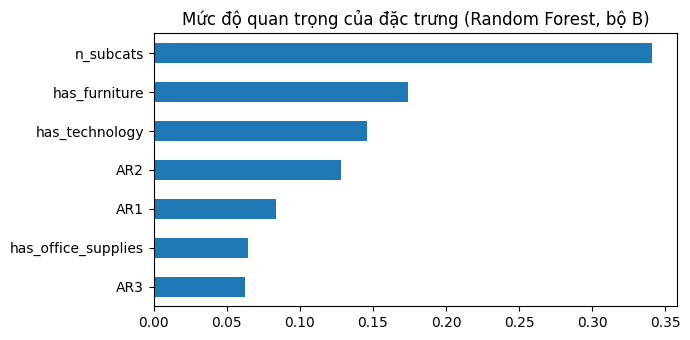

In [9]:
bo_B = bo_du_lieu['B. Baseline + luật PP1']
train_B = bo_B[bo_B['tap'] == 'train']
cot_b = [c for c in bo_B.columns if c not in ['order_id', 'tap', 'high_value']]

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
rf.fit(train_B[cot_b], train_B['high_value'])

do_quan_trong = pd.Series(rf.feature_importances_, index=cot_b).sort_values()
do_quan_trong.plot(kind='barh', figsize=(7, 3.5), title='Mức độ quan trọng của đặc trưng (Random Forest, bộ B)')
plt.tight_layout()
do_quan_trong.sort_values(ascending=False)